In [15]:
import seaborn as sb
import numpy as np
import random
import math
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import functools as ft
import statistics
import scipy as sc
import pingouin as ping
import hyppo as hyp
import random

In [ ]:
1. Моделировать броуновское движение а) с помощью случайного блуждания с нормальными шагами, б)

Построить частичные суммы в представлении Винера (в виде тригонометрических сумм) для броунов-
ского движения. Проверить, что полученный вторым путем процесс имеет независимые нормальные

приращения – измерить значения процесса в моменты i/n, найти приращения, построить ЭФР и про-
верить ее на нормальность.

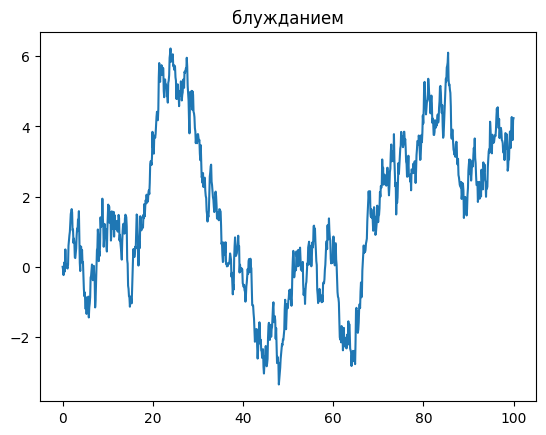

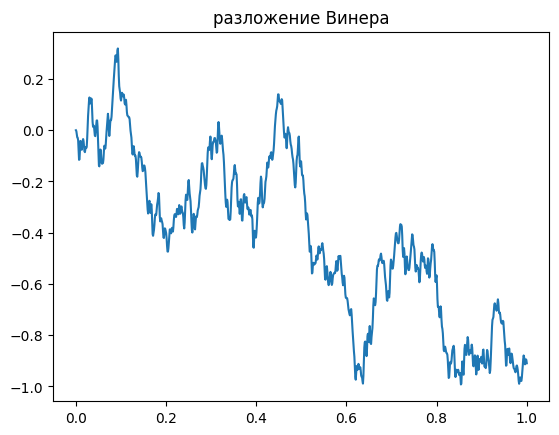

пи вэлью при проверке принадлежности приращений нормальному семейству
0.15


In [6]:
def brown_by_walk(T, N): #T-длина пути, N-насколько измельчаю отрезок
    s = np.random.normal(0, np.sqrt(T/N), size = N)
    return([ np.sum(s[:k:]) for k in range (N) ])

def brown_by_series(N):
    m = 500 # такой кусок ряда беру
    x = [0]*N
    s = np.random.normal(0, 1, size = m)
    for k in range(N):
        x[k] = np.sum( [s[n] * np.sqrt(2) * np.sin(np.pi*k/N*(n - 1/2)) / (np.pi*(n - 1/2)) for n in range(m)])
    return x
    
T = 100
N = 1000
brown = brown_by_walk(T, N)
l = np.linspace(0,T,N)
plt.plot(l, brown)
plt.title("блужданием")
plt.show()

brown = brown_by_series(N)
l = np.linspace(0,1,N)
plt.plot(l, brown)
plt.title("разложение Винера")
plt.show()

y = [0]*(N-1)
for k in range(N-1):
    y[k] = brown[k+1] - brown[k]

print("пи вэлью при проверке принадлежности приращений нормальному семейству")
print(sc.stats.anderson(y, dist = "norm", method="interpolate").pvalue)

In [ ]:
2. Моделировать Wct/√c,
tW1/t и сравнить с траекторией броуновского движения.

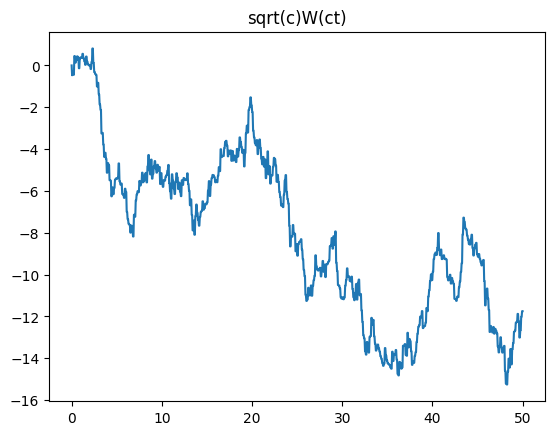

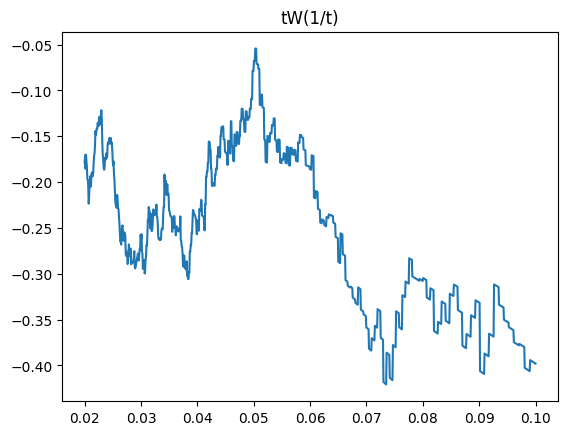

In [5]:
def brown_by_walk(T, N): #T-длина пути, N-насколько измельчаю отрезок
    s = np.random.normal(0, np.sqrt(T/N), size = N)
    return([ np.sum(s[:k:]) for k in range (N) ])

def W(t, w, T):
    if t<0 or t>T:
        print("missed")
    if t == 0:
        return 0
    if t >= T:
        return w[-1]
    N = len(w)
    for k in range(N):
        if t < k*T/N:
            return w[k]
    
T = 100
N = 1000
w = brown_by_walk(T, N)

c = 0.5 # c<1

x = [W(c*k*T/N, w, T) / np.sqrt(c) for k in range(N)]
l = np.linspace(0, T*c, N)
plt.plot(l, x)
plt.title("sqrt(c)W(ct)")
plt.show()

l = np.linspace(1/T + 0.01 , 0.1, N)
x = [t * W(1/t , w, T) for t in l]
plt.plot(l, x)
plt.title("tW(1/t)")
plt.show()

In [ ]:
Построить траекторию броуновского движения, броуновской извилины используя то, что:
фрагмент броуновского движения от τ0 до 1 совпадает по распределению (после растяжения) с
броуновской извилиной.

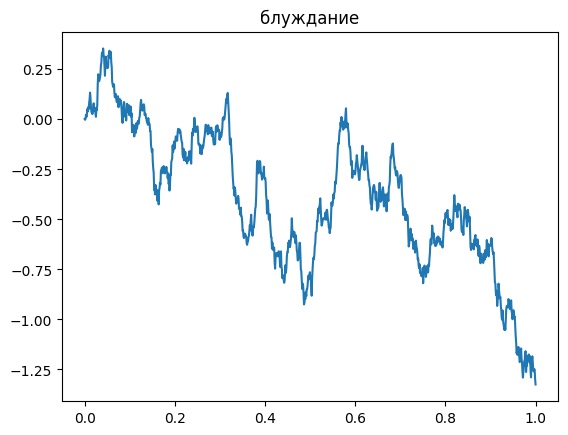

0.58


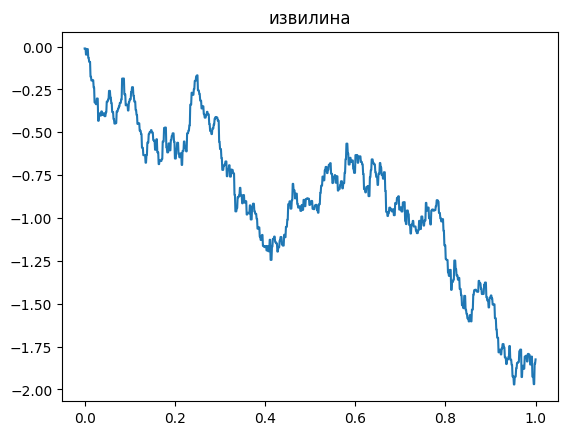

In [117]:
def brown_by_walk(T, N): #T-длина пути, N-насколько измельчаю отрезок
    s = np.random.normal(0, np.sqrt(T/N), size = N)
    return([ np.sum(s[:k:]) for k in range (N) ])

def W(t, w, T):
    if t<0 or t>T:
        print("missed W")
    N = len(w)
    for k in range(N):
        if t < k*T/N:
            return w[k]

def tau0(w, T):
    for k in range(len(w)-1, 0, -1):
        if w[k]*w[k-1] <= 0 :
            return k
    print("missed")
    
T = 1
N = 1000
w = brown_by_walk(T, N)
l = np.linspace(0,T,N)
plt.plot(l, w)
plt.title("блуждание")
plt.show()



tau = tau0(w, T)/N
print(tau)
с = 1/(T-tau)
l = np.linspace(tau, T-0.01, N)
x = [W(t, w, T) for t in l]

plt.plot(np.linspace(0, 1, N), (x-w[tau0(w, T)])/np.sqrt(T-tau))
plt.title("извилина")
plt.show()


In [ ]:
4. Исследовать закон арксинуса для ii) момента достижения максимума
 для случайного блуждания с шагами а) N (0, 1), б) (1) − 1.

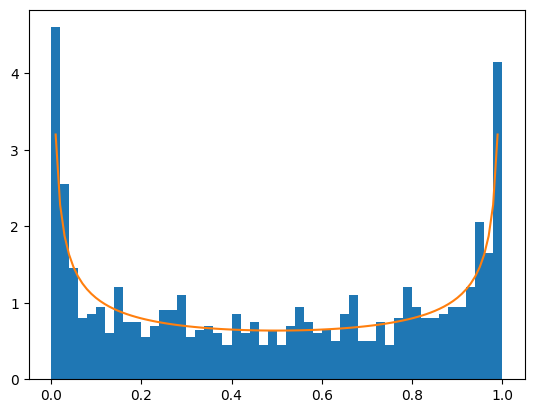

In [7]:
def brown_by_walk(T, N): #T-длина пути, N-насколько измельчаю отрезок
    s = np.random.normal(0, np.sqrt(T/N), size = N)
    return([ np.sum(s[:k:]) for k in range (N) ])

def W(t, w, T):
    if t<0 or t>T:
        print("missed W")
    N = len(w)
    for k in range(N):
        if t < k*T/N:
            return w[k]

def gen_norm(n):
    s = [0]*n
    for k in range(1,n):
        s[k]=s[k-1] + np.random.normal(0,1)
    return s
    
def maxi(s):
    m = np.max(s)
    for k in range(len(s)-1,-1,-1):
        if s[k] == m:
            return k 
n = 10000 # длина блуждания
m = 1000 # генераций
maxs = [0]*m
for k in range(m):
    s = gen_norm(n)
    maxs[k] = maxi(s)
plt.hist(np.array(maxs)/n, density = "True", bins = 50)
l = np.linspace(0.01,0.99,100)
plt.plot(l, [1/(np.pi * np.sqrt(x * (1-x))) for x in l])

In [ ]:
5. * Исследовать распределение времени, проведенного выше оси броуновским мостом, используя случай-
ное блуждание, возвращающееся в ноль (как эффективно моделировать такое блуждание?).

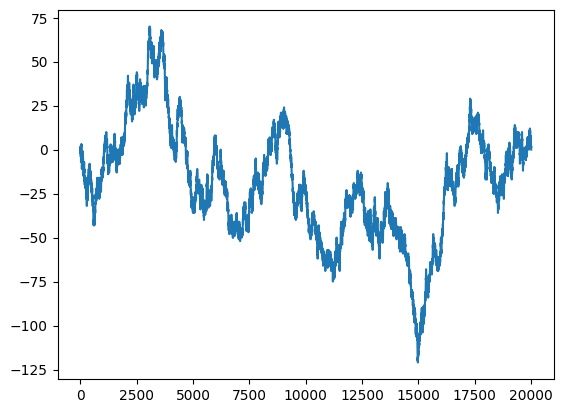

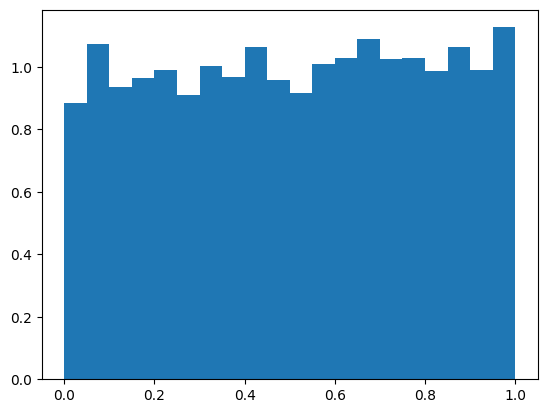

In [59]:
def walk_zero(n):
    x = np.array([1]*2*n)
    for j in range(n):
        x[j] = -1
    np.random.shuffle(x)
    s = [0]*2*n
    for j in range(1,2*n-1):
        s[j] = s[j-1] + x[j-1]
    return s

def time_high(s):
    ans = 0
    for k in range(len(s)):
        if s[k]>=0:
            ans+=1
    return ans
    
n = 10000
s = walk_zero(n)
l = np.linspace(0,2*n-1, 2*n)
plt.plot(l, s)
plt.show()

m = 10000
t = [0]*m
for k in range(m):
    s = walk_zero(n)
    t[k] = time_high(s)/(2*n-2)
plt.hist(t, density = "True", bins = 20)
plt.show()